# P17A — Deteksi objek dengan jendela geser: IoU, NMS, dan AP
Notebook ini membangun detektor paling sederhana, yaitu pengklasifikasi citra kecil yang digeser ke seluruh adegan, lalu menghitung sendiri tiga komponen evaluasi deteksi: *intersection over union* (IoU), *non-maximum suppression* (NMS), dan *average precision* (AP). Adegan adalah citra sintesis 128 × 128 piksel berisi 0–3 "lubang" (elips gelap) dan pengecoh berupa bayangan, garis sambungan, dan bintik kecil. Sasaran (lubang) memiliki lebar 14–26 piksel, sedangkan jendela berukuran tetap 24 × 24 piksel, sehingga kotak tidak pernah pas sempurna; itu disengaja untuk memperlihatkan peran IoU.

Seluruh data sintesis (seed 17017) dan hanya menguji alur kerja; angka tidak mewakili kinerja pada foto jalan nyata. Lisensi data: lihat `LICENSE-DATA.md`.


In [1]:
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from scipy.ndimage import gaussian_filter

SEED = 17017
S = 128          # sisi adegan (piksel)
W = 24           # sisi jendela geser (piksel)
torch.set_num_threads(1)
print("PyTorch", torch.__version__)

PyTorch 2.15.0+cpu


## 1. Adegan sintesis dan pembagian
Adegan dibangkitkan satu per satu dan dibagi 300 latih, 100 validasi, 100 uji. Karena tiap adegan independen, pembagian per adegan sudah mencegah kebocoran.


In [2]:
def adegan(r):
    """Satu adegan 128 x 128: latar beton, 0-3 'lubang' (elips gelap, sasaran), dan pengecoh
    (bayangan lebar, garis sambungan, bintik kecil). Mengembalikan citra dan kotak sasaran (x0, y0, x1, y1)."""
    ii, jj = np.mgrid[:S, :S]
    img = r.uniform(105, 150) + gaussian_filter(r.normal(0, 1, (S, S)), 10) * r.uniform(15, 35) \
          + gaussian_filter(r.normal(0, 1, (S, S)), 1.0) * r.uniform(7, 14) * 2.2
    kotak = []
    for _ in range(r.choice([0, 1, 2, 3], p=[0.2, 0.3, 0.3, 0.2])):
        for _coba in range(30):
            a, b = r.uniform(7, 13, 2); cx, cy = r.uniform(a + 2, S - a - 2), r.uniform(b + 2, S - b - 2)
            if all(abs(cx - (k[0] + k[2]) / 2) > 30 or abs(cy - (k[1] + k[3]) / 2) > 30 for k in kotak): break
        else: continue
        th = r.uniform(0, np.pi); u = (jj - cx) * np.cos(th) + (ii - cy) * np.sin(th); v = -(jj - cx) * np.sin(th) + (ii - cy) * np.cos(th)
        m = 1 / (1 + np.exp(((u / a) ** 2 + (v / b) ** 2 - 1) * 6))
        img = img - r.uniform(45, 85) * gaussian_filter(m, 0.8)
        mm = m > 0.5
        ys_, xs_ = np.where(mm); kotak.append((xs_.min(), ys_.min(), xs_.max() + 1, ys_.max() + 1))
    if r.random() < 0.5:                                    # bayangan lebar (pengecoh)
        c = r.uniform(0, S); th = r.uniform(0, np.pi)
        d = (jj - c) * np.cos(th) + (ii - S / 2) * np.sin(th)
        img = img - r.uniform(15, 30) * np.exp(-(d / r.uniform(10, 20)) ** 2)
    if r.random() < 0.5:                                    # garis sambungan (pengecoh)
        k = r.integers(10, S - 10)
        if r.random() < 0.5: img[k:k + 2, :] -= r.uniform(15, 30)
        else: img[:, k:k + 2] -= r.uniform(15, 30)
    for _ in range(r.integers(0, 6)):                       # bintik kecil (pengecoh)
        ci, cj = r.integers(3, S - 3, 2); img = img - r.uniform(25, 55) * np.exp(-((ii - ci) ** 2 + (jj - cj) ** 2) / (2 * r.uniform(1.0, 2.2) ** 2))
    img = img + r.normal(0, 3, (S, S))
    return np.clip(img, 0, 255).astype(np.uint8), np.array(kotak, float).reshape(-1, 4)

rng = np.random.default_rng(SEED)
data = [adegan(rng) for _ in range(500)]
latih, valid, uji = data[:300], data[300:400], data[400:]
print("adegan latih/validasi/uji:", len(latih), len(valid), len(uji))
print("jumlah lubang (latih/validasi/uji):", sum(len(k) for _, k in latih), sum(len(k) for _, k in valid), sum(len(k) for _, k in uji))
uk = np.concatenate([(k[:, 2] - k[:, 0], k[:, 3] - k[:, 1]) for _, k in data if len(k)], axis=1)
print("lebar kotak sasaran (px): min %.0f median %.0f maks %.0f" % (uk[0].min(), np.median(uk[0]), uk[0].max()))

/tmp/ipykernel_969/2744553294.py:14: RuntimeWarning: overflow encountered in exp
  m = 1 / (1 + np.exp(((u / a) ** 2 + (v / b) ** 2 - 1) * 6))


adegan latih/validasi/uji: 300 100 100
jumlah lubang (latih/validasi/uji): 487 143 169
lebar kotak sasaran (px): min 14 median 20 maks 26


## 2. IoU dan NMS buatan sendiri
IoU adalah luas irisan dibagi luas gabungan dua kotak. NMS mempertahankan kotak dengan skor tertinggi dan membuang kotak lain yang IoU-nya dengan kotak itu melebihi ambang. Implementasi sendiri diperiksa terhadap `torchvision.ops.nms`.


In [3]:
def iou(a, b):
    """IoU antara satu kotak a (4,) dan banyak kotak b (n,4)."""
    b = np.atleast_2d(b)
    iw = np.clip(np.minimum(a[2], b[:, 2]) - np.maximum(a[0], b[:, 0]), 0, None)
    ih = np.clip(np.minimum(a[3], b[:, 3]) - np.maximum(a[1], b[:, 1]), 0, None)
    inter = iw * ih
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]) - inter)

def nms(kotak, skor, ambang):
    urut = np.argsort(-skor); pilih = []
    while len(urut):
        i = urut[0]; pilih.append(i)
        urut = urut[1:][iou(kotak[i], kotak[urut[1:]]) < ambang] if len(urut) > 1 else urut[1:]
    return np.array(pilih, int)

print("IoU contoh: kotak 24x24 vs sasaran 16x16 sepusat =", round(float(iou(np.array([0, 0, 24, 24.]), np.array([[4, 4, 20, 20.]]))[0]), 3),
      "| vs 28x28 sepusat =", round(float(iou(np.array([0, 0, 24, 24.]), np.array([[-2, -2, 26, 26.]]))[0]), 3))
# pemeriksaan terhadap torchvision.ops.nms
import torchvision
tb = np.random.default_rng(1).uniform(0, 60, (40, 2)); tb = np.c_[tb, tb + np.random.default_rng(2).uniform(10, 30, (40, 2))]; ts = np.random.default_rng(3).random(40)
ref = torchvision.ops.nms(torch.tensor(tb, dtype=torch.float32), torch.tensor(ts, dtype=torch.float32), 0.3).numpy()
print("NMS buatan sendiri sama dengan torchvision:", set(nms(tb, ts, 0.3)) == set(ref.tolist()))

IoU contoh: kotak 24x24 vs sasaran 16x16 sepusat = 0.444 | vs 28x28 sepusat = 0.735


NMS buatan sendiri sama dengan torchvision: True


## 3. Pengklasifikasi jendela
Positif: jendela yang digeser acak ±4 piksel dari pusat lubang. Negatif: jendela dengan IoU < 0,10 terhadap semua lubang. CNN kecil yang sama gayanya dengan Bab 16 dilatih dengan early stopping.


In [4]:
def potong(img, x, y): return img[y:y + W, x:x + W]
def buat_jendela(daftar, r, n_neg_per=14, jitter=4):
    X, y = [], []
    for img, kb in daftar:
        for k in kb:                                         # positif: jendela di sekitar pusat lubang
            cx, cy = (k[0] + k[2]) / 2, (k[1] + k[3]) / 2
            for _ in range(6):
                x0 = int(np.clip(round(cx - W / 2 + r.integers(-jitter, jitter + 1)), 0, S - W)); y0 = int(np.clip(round(cy - W / 2 + r.integers(-jitter, jitter + 1)), 0, S - W))
                X.append(potong(img, x0, y0)); y.append(1)
        for _ in range(n_neg_per):                           # negatif: jendela dengan IoU rendah terhadap semua sasaran
            for _c in range(50):
                x0, y0 = r.integers(0, S - W + 1, 2)
                if len(kb) == 0 or iou(np.array([x0, y0, x0 + W, y0 + W], float), kb).max() < 0.10: break
            else: continue
            X.append(potong(img, x0, y0)); y.append(0)
    return np.stack(X), np.array(y)
rj = np.random.default_rng(SEED + 1)
Xtr, ytr = buat_jendela(latih, rj); Xva, yva = buat_jendela(valid, rj)
print("jendela latih:", Xtr.shape, "positif %.2f" % ytr.mean(), "| validasi:", Xva.shape, "positif %.2f" % yva.mean())

jendela latih: (7122, 24, 24) positif 0.41 | validasi: (2258, 24, 24) positif 0.38


In [5]:
class CNNJendela(nn.Module):
    def __init__(s):
        super().__init__()
        s.f = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                            nn.Flatten(), nn.Linear(16 * (W // 4) ** 2, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(s, x): return s.f(x).squeeze(1)
def ke_tensor(X): return torch.tensor((X.astype(np.float32) / 255 - 0.5) / 0.25).unsqueeze(1)
torch.manual_seed(SEED)
net = CNNJendela(); print("parameter:", sum(p.numel() for p in net.parameters()))
opt = torch.optim.Adam(net.parameters(), 3e-3); lossf = nn.BCEWithLogitsLoss()
Ttr, Tva = ke_tensor(Xtr), ke_tensor(Xva); Ytr, Yva = torch.tensor(ytr, dtype=torch.float32), torch.tensor(yva, dtype=torch.float32)
terbaik, simpan, sabar = 1e9, None, 0
for ep in range(60):
    net.train(); perm = torch.randperm(len(Ttr))
    for i in range(0, len(perm), 64):
        b = perm[i:i + 64]; opt.zero_grad(); lossf(net(Ttr[b]), Ytr[b]).backward(); opt.step()
    net.eval()
    with torch.no_grad(): lv = lossf(net(Tva), Yva).item()
    if lv < terbaik - 1e-4: terbaik, simpan, sabar = lv, {k: v.clone() for k, v in net.state_dict().items()}, 0
    else:
        sabar += 1
        if sabar >= 8: break
net.load_state_dict(simpan); net.eval()
with torch.no_grad(): pv = (net(Tva) > 0).numpy()
print("epoch dijalankan:", ep + 1, "| akurasi jendela validasi: %.3f" % (pv == yva).mean())

parameter: 19745


epoch dijalankan: 17 | akurasi jendela validasi: 1.000


## 4. Jendela geser, NMS, dan evaluasi
Jendela digeser dengan langkah 4 piksel. Kandidat berskor ≥ 0,05 dipangkas dengan NMS (IoU 0,3). Sebuah deteksi dihitung benar bila IoU-nya dengan lubang yang belum terpakai ≥ ambang.


In [6]:
STRIDE = 4
def skor_peta(img):
    """Skor peluang tiap posisi jendela (stride 4); mengembalikan kotak (n,4) dan skor (n,)."""
    pos = [(x, y) for y in range(0, S - W + 1, STRIDE) for x in range(0, S - W + 1, STRIDE)]
    T = ke_tensor(np.stack([potong(img, x, y) for x, y in pos]))
    with torch.no_grad(): p = torch.sigmoid(net(T)).numpy()
    return np.array([[x, y, x + W, y + W] for x, y in pos], float), p
def deteksi(img, ambang_skor=0.05, ambang_nms=0.3):
    kb, p = skor_peta(img); m = p >= ambang_skor; kb, p = kb[m], p[m]
    if len(p) == 0: return kb, p
    k = nms(kb, p, ambang_nms); return kb[k], p[k]
t0 = time.perf_counter(); semua = [(deteksi(img), kb) for img, kb in uji]; print("waktu 100 adegan uji: %.1f detik" % (time.perf_counter() - t0))
mentah = [skor_peta(img) for img, _ in uji[:1]]
print("kandidat sebelum NMS pada adegan 0 (skor >= 0,05):", int((mentah[0][1] >= 0.05).sum()), "| sesudah NMS:", len(semua[0][0][0]))

waktu 100 adegan uji: 3.1 detik
kandidat sebelum NMS pada adegan 0 (skor >= 0,05): 45 | sesudah NMS: 5


In [7]:
def ap_pada(semua, iou_min):
    rec = []  # (skor, tp?)
    n_gt = sum(len(kb) for _, kb in semua)
    for (db, ds), kb in semua:
        terpakai = np.zeros(len(kb), bool)
        for i in np.argsort(-ds):
            if len(kb):
                v = iou(db[i], kb); v[terpakai] = -1; j = int(np.argmax(v))
                if v[j] >= iou_min: terpakai[j] = True; rec.append((ds[i], 1)); continue
            rec.append((ds[i], 0))
    rec.sort(key=lambda t: -t[0]); tp = np.cumsum([t[1] for t in rec]); fp = np.cumsum([1 - t[1] for t in rec])
    rc = tp / n_gt; pr = tp / (tp + fp)
    mpre = np.maximum.accumulate(np.r_[pr, 0][::-1])[::-1]; mrec = np.r_[0, rc]
    ap = float(np.sum((mrec[1:] - mrec[:-1]) * mpre[:len(rc)] if len(rc) else 0))
    return ap, rc, pr, n_gt
hasil_ap = {t: ap_pada(semua, t)[0] for t in (0.3, 0.4, 0.5, 0.6, 0.7)}
for t, a in hasil_ap.items(): print("AP pada IoU >= %.1f: %.3f" % (t, a))
print("jumlah sasaran uji:", ap_pada(semua, 0.5)[3], "| jumlah deteksi:", sum(len(d[1]) for d, _ in semua))

AP pada IoU >= 0.3: 0.639
AP pada IoU >= 0.4: 0.514
AP pada IoU >= 0.5: 0.271
AP pada IoU >= 0.6: 0.039
AP pada IoU >= 0.7: 0.007
jumlah sasaran uji: 169 | jumlah deteksi: 413


Titik operasi dan jenis alarm palsu. Perhatikan bahwa skor pengklasifikasi hampir jenuh (0 atau 1), sehingga menggeser ambang skor hanya sedikit mengubah hasil.


In [8]:
print("ambang | recall (IoU >= 0,4) | alarm palsu per adegan | di antaranya dekat sasaran (IoU > 0) | di latar murni")
for th in (0.999, 0.99, 0.9, 0.5, 0.1):
    tp = fp = dekat = 0; n = 0
    for (db, ds), kb in semua:
        m = ds >= th; terpakai = np.zeros(len(kb), bool)
        for i in np.argsort(-ds[m]):
            b = db[m][i]
            if len(kb):
                v = iou(b, kb); v2 = v.copy(); v2[terpakai] = -1; j = int(np.argmax(v2))
                if v2[j] >= 0.4: terpakai[j] = True; tp += 1; continue
                if v.max() > 0: dekat += 1
            fp += 1
        n += len(kb)
    print(f"{th:6.3f} | {tp / n:6.3f} | {fp / len(semua):6.2f} | {dekat / max(fp, 1):.2f} | {1 - dekat / max(fp, 1):.2f}")

ambang | recall (IoU >= 0,4) | alarm palsu per adegan | di antaranya dekat sasaran (IoU > 0) | di latar murni
 0.999 |  0.899 |   1.63 | 1.00 | 0.00
 0.990 |  0.899 |   1.87 | 0.99 | 0.01
 0.900 |  0.899 |   2.09 | 0.99 | 0.01
 0.500 |  0.899 |   2.22 | 0.99 | 0.01
 0.100 |  0.899 |   2.50 | 0.97 | 0.03


Recall menurut ukuran sasaran.


In [9]:
bins = [(14, 18), (18, 22), (22, 26), (26, 30)]
print("lebar sasaran | n | recall pada skor >= 0,5 dan IoU >= 0,4")
for lo, hi in bins:
    n = tp = 0
    for (db, ds), kb in semua:
        for k in kb:
            w = k[2] - k[0]
            if lo <= w < hi:
                n += 1; m = ds >= 0.5
                if m.any() and iou(k, db[m]).max() >= 0.4: tp += 1
    print(f"{lo}-{hi} px | {n} | {tp / max(n, 1):.3f}")

lebar sasaran | n | recall pada skor >= 0,5 dan IoU >= 0,4
14-18 px | 48 | 0.646
18-22 px | 62 | 1.000
22-26 px | 57 | 1.000
26-30 px | 2 | 1.000


## 5. Gambar


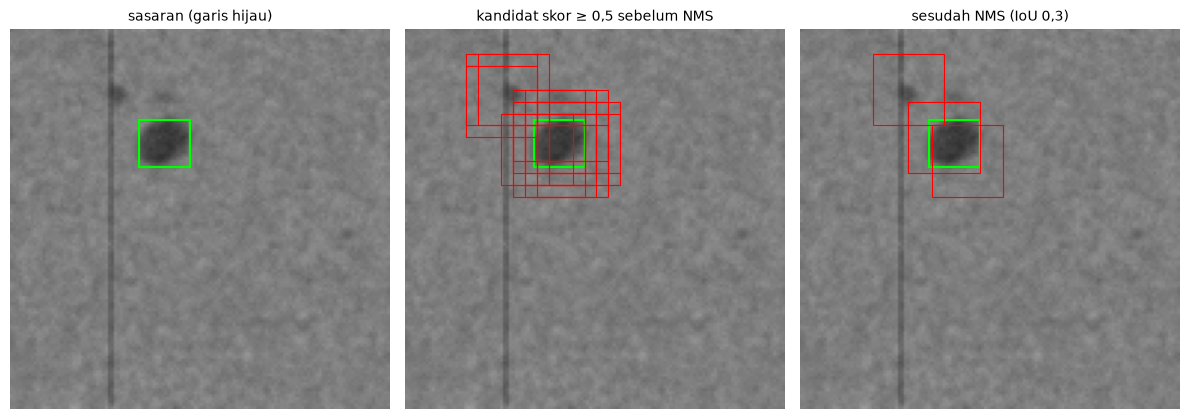

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4.2))
img, kb = uji[2]
kb_m, p_m = skor_peta(img); m = p_m >= 0.5
for a, (judul, boxes, sk) in zip(ax, [("sasaran (garis hijau)", None, None), ("kandidat skor ≥ 0,5 sebelum NMS", kb_m[m], p_m[m]), ("sesudah NMS (IoU 0,3)", *deteksi(img, 0.5))]):
    a.imshow(img, cmap="gray", vmin=0, vmax=255); a.set_title(judul, fontsize=10); a.axis("off")
    for k in kb: a.add_patch(plt.Rectangle((k[0], k[1]), k[2] - k[0], k[3] - k[1], fill=False, ec="lime", lw=1.6))
    if boxes is not None:
        for b in boxes: a.add_patch(plt.Rectangle((b[0], b[1]), W, W, fill=False, ec="red", lw=0.8))
plt.tight_layout(); plt.show()

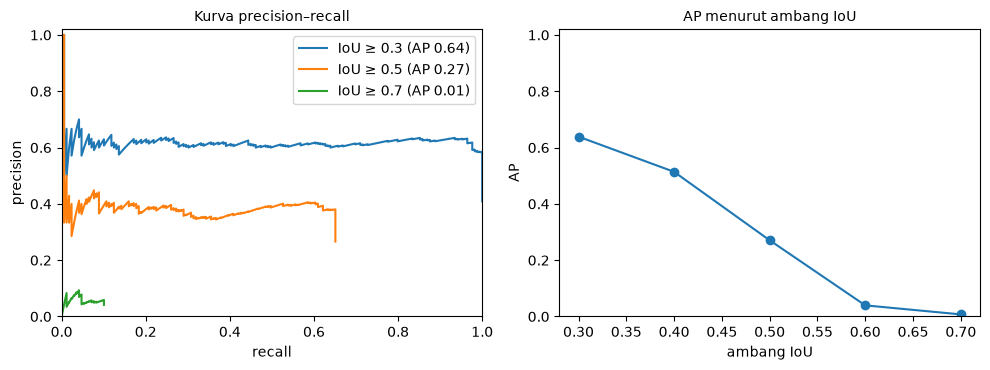

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for t in (0.3, 0.5, 0.7):
    a_, rc, pr, _ = ap_pada(semua, t); ax[0].plot(rc, pr, label=f"IoU ≥ {t:.1f} (AP {a_:.2f})")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1.02); ax[0].legend(); ax[0].set_title("Kurva precision–recall", fontsize=10)
ax[1].plot(list(hasil_ap), list(hasil_ap.values()), "o-"); ax[1].set_xlabel("ambang IoU"); ax[1].set_ylabel("AP"); ax[1].set_ylim(0, 1.02); ax[1].set_title("AP menurut ambang IoU", fontsize=10)
plt.tight_layout(); plt.show()

## 6. Variasi antarbenih
Pengklasifikasi dilatih ulang dengan lima benih; AP dihitung pada adegan uji yang sama.


In [12]:
def latih_ulang(seed):
    torch.manual_seed(seed); n = CNNJendela(); o = torch.optim.Adam(n.parameters(), 3e-3); tb, sv, sb = 1e9, None, 0
    for ep in range(60):
        n.train(); perm = torch.randperm(len(Ttr))
        for i in range(0, len(perm), 64):
            b = perm[i:i + 64]; o.zero_grad(); lossf(n(Ttr[b]), Ytr[b]).backward(); o.step()
        n.eval()
        with torch.no_grad(): lv = lossf(n(Tva), Yva).item()
        if lv < tb - 1e-4: tb, sv, sb = lv, {k: v.clone() for k, v in n.state_dict().items()}, 0
        else:
            sb += 1
            if sb >= 8: break
    n.load_state_dict(sv); n.eval(); return n
global_net = net; aps = []
for sd in (1, 2, 3, 4, 5):
    net = latih_ulang(SEED + 100 + sd)
    aps.append((ap_pada([(deteksi(img), kb) for img, kb in uji], 0.5)[0], ap_pada([(deteksi(img), kb) for img, kb in uji], 0.4)[0]))
net = global_net
aps = np.array(aps); print("AP@0,5 lima benih: rerata %.3f, sd %.3f | AP@0,4: rerata %.3f, sd %.3f" % (aps[:, 0].mean(), aps[:, 0].std(ddof=1), aps[:, 1].mean(), aps[:, 1].std(ddof=1)))

AP@0,5 lima benih: rerata 0.314, sd 0.059 | AP@0,4: rerata 0.563, sd 0.065


**Catatan batas.** Detektor jendela geser tidak meregresi kotak, sehingga IoU dibatasi oleh ukuran jendela. Detektor modern (keluarga YOLO, Faster R-CNN) menambahkan regresi kotak dan banyak skala. Adegan ini sintesis dan sederhana; angka AP hanya untuk belajar membaca metrik.
